# Zložky sily v hre EXACT FORCE: kolísanie pri ovládaní hry vs. tras

**Úloha:** navrhnúť analýzu, ktorá oddelí dve zložky signálu sily – (1) kolísanie sily pri ovládaní hry
(vedomé korekcie, pomalé) a (2) tras (nevedomý, rýchlejší a rytmický). Analýza do 15 Hz. Výstupom má byť
pre každého človeka niekoľko hodnôt (priemerná amplitúda zložiek, priemerná frekvencia, smerodajná
odchýlka …), na základe ktorých sa neskôr bude rozhodovať, či ide o pacienta. Pozor na pacientov, ktorí
jednu ruku nepoužívajú alebo len málo.

Postup:
0. výber dát (kto je kto, ktoré súbory),
1. predspracovanie signálu,
2. **určenie hranice medzi zložkami z dát**,
3. **rozdelenie na zložky a ustálené úseky**,
4. **neaktívne prsty a ruky**,
5. **príznaky**, 6. **tabuľka `features.csv`**,
7. **porovnanie skupín**.

## 0. Výber dát

Označenie pacient/zdravý je v CSV súboroch v priečinku `datasets`:
`dataset_patients.csv` (pacienti), `dataset_tuke.csv` (zdraví – študenti a zamestnanci TUKE, február 2025),
`dataset_99.csv` (zdraví – starší ľudia, september 2026). Z každého vyšetrenia berieme hlavný krok
**EXACT_FORCE** (4 iterácie po 16 s). Pacienti boli meraní inou verziou scenára, preto má krok iný `step_id`.
Pacienti majú väčšinou 2 vyšetrenia; do tabuľky ľudí sa neskôr spriemerujú.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rehapiano_features import (EXACT_FORCE_STEPS, FS_OUT, T0, T1, build_exam_table, finger_psd,
                                load_all)

exams, unlabelled = build_exam_table()
display(exams.groupby("podskupina").agg(vysetreni=("measurement_id", "size"),
                                        ludi=("patient_id", "nunique"),
                                        vek_median=("vek", "median"),
                                        vek_min=("vek", "min"), vek_max=("vek", "max")))
print("Vyšetrení bez súboru na disku:", exams.path.isna().sum())
print("Súbory EXACT_FORCE bez označenia v CSV (vynechané):")
display(unlabelled[["folder", "exam"]])

,vysetreni,ludi,vek_median,vek_min,vek_max
podskupina,,,,,
pacienti,83,48,66.0,21,89
zdraví 9_9_2026 (starší),12,12,69.0,56,85
zdraví TUKE 2025-02,78,78,23.0,18,79


Vyšetrení bez súboru na disku: 0
Súbory EXACT_FORCE bez označenia v CSV (vynechané):


,folder,exam
0,22_08_2025,e2200e8f-312a-4819-9462-33f21dbc0af3
1,22_08_2025,028889d8-b722-4ab7-838b-3fd60aeb5edd
2,28_02_2025,8c96c3b4-92ae-41d6-ab8b-316992055824
3,9_9_2026,7d55e12b-66df-4ca6-9ef3-27a880edec7a


## 1. Predspracovanie

Pre každé vyšetrenie a každú iteráciu:
1. načítanie a prevzorkovanie na rovnomernú mriežku 1000 Hz, doplnenie NaN (modul `rehapiano_io.py`),
2. **decimácia na 100 Hz** – analýza je len do 15 Hz a na zachytenie frekvencie *f* stačí viac ako 2·*f*
   vzoriek za sekundu; FIR filter pred decimáciou odstráni frekvencie nad ~40 Hz (proti aliasingu),
3. vyrezanie úseku **3–15 s** (začiatok iterácie je nastavovanie sily, koniec uvoľnenie).

Iterácie sa nespájajú – každá je samostatný záznam. Výsledok sa uloží do `cache/exact_force_100hz.npz`,
aby sa súbory nemuseli dekódovať znova.

In [2]:
X, n_nan = load_all(exams)           # tvar: (vyšetrenia, 4 iterácie, 1200 vzoriek, 10 prstov)
print("Tvar dát:", X.shape, "| vzorkovacia frekvencia:", FS_OUT, "Hz | úsek:", T0, "–", T1, "s")
exams["doplnenych_NaN"] = n_nan
display(exams.groupby("podskupina").doplnenych_NaN.describe()[["mean", "50%", "max"]].round(0))

Tvar dát: (173, 4, 1200, 10) | vzorkovacia frekvencia: 100.0 Hz | úsek: 3.0 – 15.0 s


,mean,50%,max
podskupina,,,
pacienti,582.0,490.0,2120.0
zdraví 9_9_2026 (starší),972.0,832.0,2460.0
zdraví TUKE 2025-02,271.0,42.0,2250.0


### Nastavenia grafov

In [3]:
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
GROUPS = ["zdraví TUKE 2025-02", "zdraví 9_9_2026 (starší)", "pacienti"]
COLORS = {"zdraví TUKE 2025-02": "#2a78d6", "zdraví 9_9_2026 (starší)": "#1baf7a", "pacienti": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
    "figure.dpi": 110,
})
FIG_DIR = __import__("pathlib").Path("figures"); FIG_DIR.mkdir(exist_ok=True)

## 2. Hranica medzi zložkami – určená z dát

**Myšlienka:** vedomé korekcie sily sú pomalé (človek vidí silu na obrazovke a dorovnáva ju), preto ich
energia je sústredená na nízkych frekvenciách a smerom nahor rýchlo klesá. Nad určitou frekvenciou
pokles spomalí – tam už dominuje tras a šum. Túto hranicu („koleno" spektra) hľadáme v dátach.

Pre každé vyšetrenie: Welchova výkonová spektrálna hustota (PSD; segmenty 4 s, Δf = 0,25 Hz, lineárny
detrend) pre každý prst, priemer cez **aktívne prsty** (priemerná sila > 0,003) a cez 4 iterácie.
Potom medián v rámci skupiny.

In [4]:
LEVEL_MIN = 0.003      # prst s menšou priemernou silou sa považuje za nepoužitý (krok 4 to spresní)

def exam_psd(x_exam):
    ps = []
    for it in x_exam:
        f, p = finger_psd(it)
        active = np.abs(it.mean(axis=0)) > LEVEL_MIN
        ps.append(p[:, active].mean(axis=1) if active.any() else np.full(len(f), np.nan))
    return f, np.nanmean(ps, axis=0)

PSD = np.array([exam_psd(X[e])[1] for e in range(len(exams))])
F = exam_psd(X[0])[0]
band = (F >= 0.25) & (F <= 15)


def knee(y):
    # Zlom spektra: dve priamky v log10(PSD) vs. f, hľadá sa bod zlomu s najmenšou chybou.
    fm, ly = F[band], np.log10(y[band])
    best = None
    for k in range(3, len(fm) - 3):
        sse = 0.0
        for sl in (slice(0, k + 1), slice(k, None)):
            c = np.polyfit(fm[sl], ly[sl], 1)
            sse += np.sum((np.polyval(c, fm[sl]) - ly[sl]) ** 2)
        if best is None or sse < best[0]:
            best = (sse, fm[k])
    return best[1]


rows = []
for g in GROUPS:
    sel = (exams.podskupina == g).to_numpy()
    per_exam = [knee(PSD[i]) for i in np.where(sel)[0]]
    rows.append(dict(skupina=g, vysetreni=int(sel.sum()), koleno_medianu_PSD_Hz=knee(np.median(PSD[sel], axis=0)),
                     koleno_vysetrenia_median_Hz=np.median(per_exam),
                     koleno_IQR_Hz=f"{np.percentile(per_exam, 25):.2f}–{np.percentile(per_exam, 75):.2f}"))
knees = pd.DataFrame(rows)
display(knees)

,skupina,vysetreni,koleno_medianu_PSD_Hz,koleno_vysetrenia_median_Hz,koleno_IQR_Hz
0,zdraví TUKE 2025-02,78,3.25,3.250,2.75–4.19
1,zdraví 9_9_2026 (starší),12,2.50,5.125,4.44–5.50
2,pacienti,83,3.25,3.500,2.75–4.25


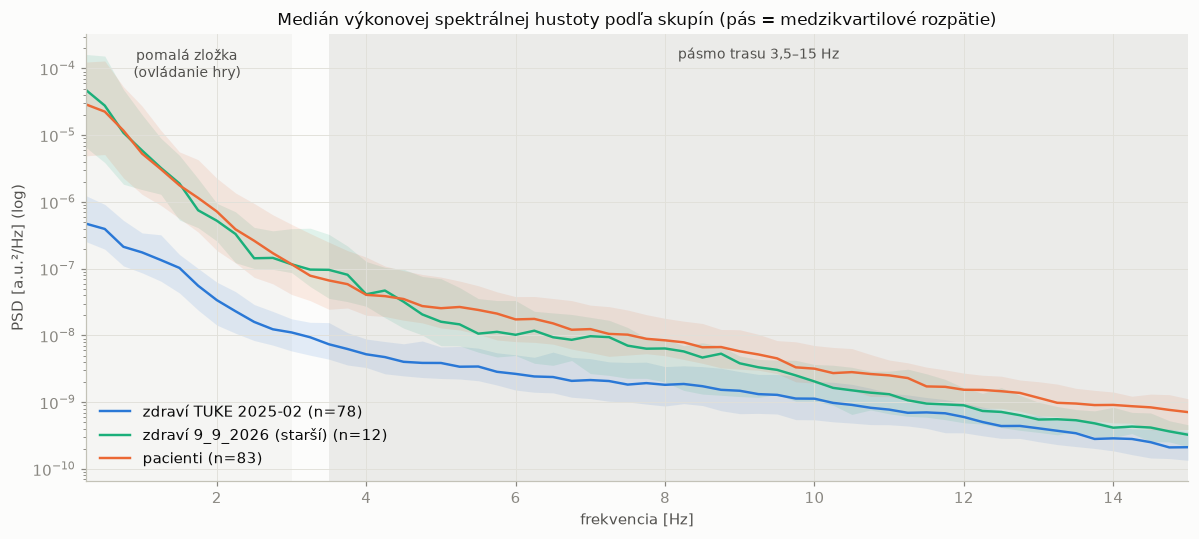

In [5]:
SLOW_MAX, TREMOR_BAND = 3.0, (3.5, 15.0)

fig, ax = plt.subplots(figsize=(11, 5))
for g in GROUPS:
    sel = (exams.podskupina == g).to_numpy()
    q25, med, q75 = np.percentile(PSD[sel][:, band], [25, 50, 75], axis=0)
    ax.fill_between(F[band], q25, q75, color=COLORS[g], alpha=0.12, lw=0)
    ax.plot(F[band], med, color=COLORS[g], label=f"{g} (n={sel.sum()})")
ax.set_yscale("log")
ax.axvspan(0.25, SLOW_MAX, color=MUTED, alpha=0.06, lw=0)
ax.axvspan(*TREMOR_BAND, color=MUTED, alpha=0.14, lw=0)
ax.text(1.6, 0.97, "pomalá zložka\n(ovládanie hry)", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color=INK2)
ax.text(9.25, 0.97, "pásmo trasu 3,5–15 Hz", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color=INK2)
ax.set_xlim(0.25, 15)
ax.set_xlabel("frekvencia [Hz]"); ax.set_ylabel("PSD [a.u.²/Hz] (log)")
ax.set_title("Medián výkonovej spektrálnej hustoty podľa skupín (pás = medzikvartilové rozpätie)")
ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(FIG_DIR / "10_psd_skupiny.png", dpi=150); plt.show()

**Výsledok:** vo všetkých skupinách PSD do ~3 Hz strmo klesá (o 2–3 rády) a potom pokles výrazne spomalí.
Zlom spektra mediánu je pri **~3,25 Hz** u pacientov aj u zdravých TUKE (u 12 starších zdravých ~2,5 Hz).
Navrhovaná hranica:

- **pomalá zložka (ovládanie hry): 0–3 Hz**,
- **tras: 3,5–15 Hz** (dolná hranica rovnaká ako v článku o Rehapiane, Ferenčík et al., 2020),
- prechodové pásmo 3–3,5 Hz sa nepriraďuje žiadnej zložke (filtre nemajú ostrú hranu).

### Dôležité zistenie: skupiny neboli merané v rovnakých podmienkach

Úroveň PSD sa medzi skupinami líši až o dva rády. Rozhoduje však najmä **obdobie merania**, nie vek ani
choroba: ľudia z TUKE vo veku ≥ 50 rokov majú výkon pomalej zložky len ~3× väčší ako mladí z TUKE, ale
~20× menší ako rovnako starí zdraví ľudia z 9_9_2026 – hoci priemerná úroveň sily je vo všetkých skupinách
takmer rovnaká (~0,021). Pacienti (≥ 50) a zdraví 9_9_2026 majú naopak oba výkony veľmi podobné.

In [6]:
def band_power(f, p, lo, hi):
    m = (f >= lo) & (f < hi)
    return float(np.sum(p[m]) * (f[1] - f[0]))

exams["vykon_pomaly"] = [band_power(F, PSD[i], 0.0, SLOW_MAX) for i in range(len(exams))]
exams["vykon_tras"] = [band_power(F, PSD[i], *TREMOR_BAND) for i in range(len(exams))]
exams["uroven_sily"] = [float(np.mean([np.abs(it.mean(0))[np.abs(it.mean(0)) > LEVEL_MIN].mean() for it in X[i]]))
                        for i in range(len(exams))]
exams["vekova_skupina"] = np.where(exams.vek >= 50, "≥ 50", "< 50")
summary = exams.groupby(["podskupina", "vekova_skupina"]).agg(
    vysetreni=("measurement_id", "size"), uroven_sily=("uroven_sily", "median"),
    vykon_pomaly=("vykon_pomaly", "median"), vykon_tras=("vykon_tras", "median"))
display(summary.style.format({"uroven_sily": "{:.4f}", "vykon_pomaly": "{:.1e}", "vykon_tras": "{:.1e}"}))

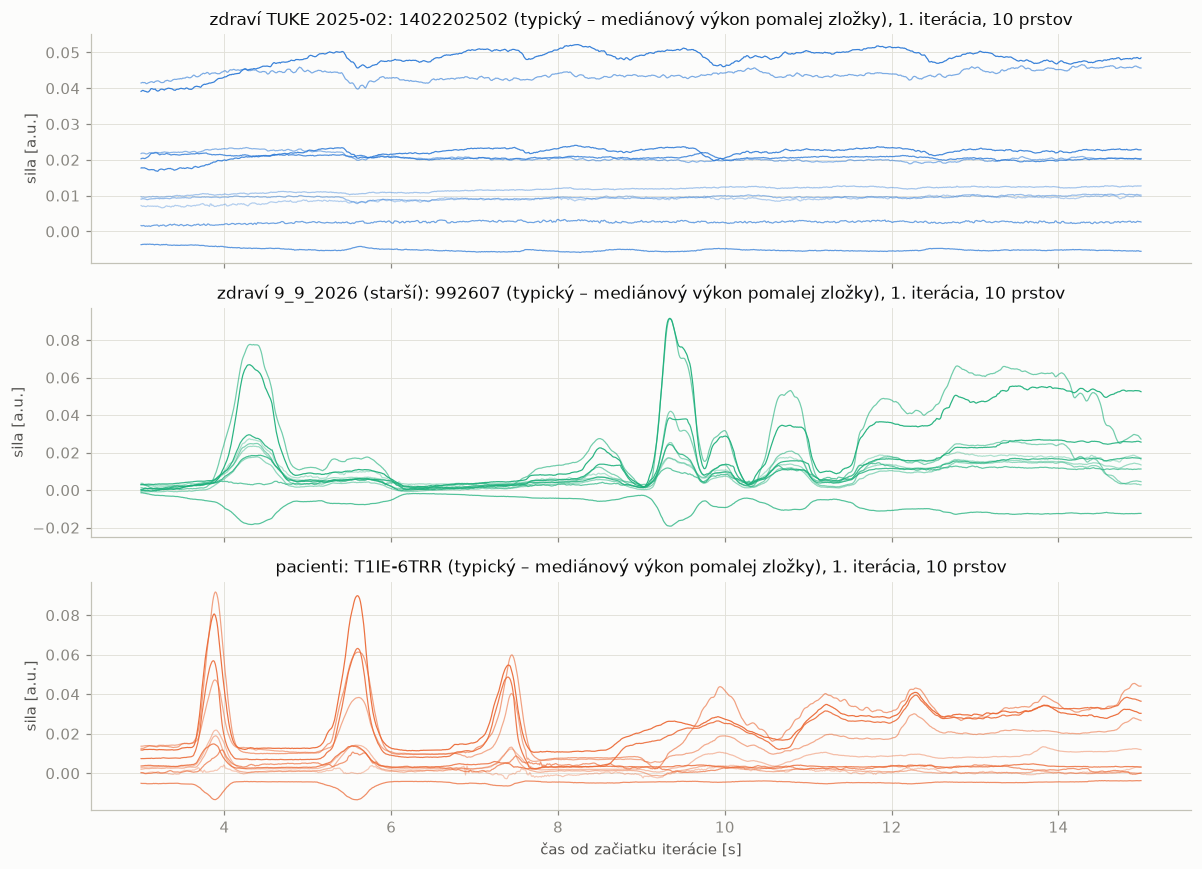

In [7]:
# typický predstaviteľ skupiny = vyšetrenie s mediánovým výkonom pomalej zložky
def typical(g):
    sub = exams[exams.podskupina == g]
    return (sub.vykon_pomaly - sub.vykon_pomaly.median()).abs().idxmin()

fig, axes = plt.subplots(len(GROUPS), 1, figsize=(11, 8), sharex=True)
t = T0 + np.arange(X.shape[2]) / FS_OUT
for ax, g in zip(axes, GROUPS):
    e = typical(g)
    for c in range(X.shape[3]):
        ax.plot(t, X[e, 0, :, c], lw=0.8, color=COLORS[g], alpha=0.35 + 0.065 * c)
    ax.set_title(f"{g}: {exams.patient_id[e]} (typický – mediánový výkon pomalej zložky), 1. iterácia, 10 prstov")
    ax.set_ylabel("sila [a.u.]")
axes[-1].set_xlabel("čas od začiatku iterácie [s]")
fig.tight_layout(); fig.savefig(FIG_DIR / "11_priklady_signalov.png", dpi=150); plt.show()

Na príkladoch je vidieť, prečo: v meraniach z obdobia po februári 2025 (pacienti aj zdraví 9_9_2026)
ľudia počas iterácie často **prudko pritlačia a povolia** (skoky sily až do ~0,3), kým vo februári 2025
držali silu takmer rovnomerne. Príčinou môže byť iná verzia hry, iné pokyny alebo nastavenie – z dát to
nevieme určiť (treba sa opýtať).

**Dôsledky pre ďalšie kroky:**
1. **Zdraví TUKE nie sú priamo porovnateľní** s pacientmi – klasifikátor by sa mohol naučiť rozlišovať
   obdobie merania namiesto choroby. Hlavné porovnanie: pacienti vs. zdraví 9_9_2026 (rovnaké obdobie),
   TUKE len ako doplnok.
2. **Skoky sily „presakujú" do pásma trasu:** ostrá hrana skoku má energiu na všetkých frekvenciách.
   Preto sa v kroku 3 bude tras merať len v úsekoch **ustáleného držania sily** (bez skokov) – inak by sme
   ako „tras" počítali aj prudké pohyby pri ovládaní hry.

## 3. Rozdelenie signálu na dve zložky

Každý prst v každej iterácii rozdelíme filtrami (Butterworth 4. rádu, obojsmerná filtrácia – bez
fázového posunu, zložky sú časovo zarovnané so signálom):

- **pomalá zložka** = dolnopriepustný filter **do 3 Hz** – vedomé korekcie sily pri ovládaní hry,
- **tras** = pásmový filter **3,5–15 Hz** – nevedomé rytmické chvenie.

### Ustálené úseky

Prudké pritlačenie a povolenie (skok sily) má ostrú hranu a jeho energia „presakuje" aj do pásma
3,5–15 Hz. Tras preto meriame len v **úsekoch ustáleného držania sily**:

1. z pomalej zložky vypočítame rýchlosť zmeny sily (a.u./s),
2. **skok** = miesto, kde je rýchlosť väčšia ako **8× typická (mediánová) rýchlosť daného prsta v danej
   iterácii** a zároveň aspoň 0,01 a.u./s,
3. okolo skokov vynecháme 0,25 s (dozvuk filtra) a ponecháme súvislé úseky dlhé aspoň 2 s.

Prah je zámerne **relatívny k človeku**. Pevný prah (napr. 0,01 a.u./s pre všetkých) zlyhal: pacientka
ILHC-BZCP má tras v zhlukoch, ktoré posúvajú aj pomalú zložku, a pevný prah označil celý jej signál ako
„skok" – tras by úplne zmizol z analýzy (overené nižšie).

In [8]:
from rehapiano_features import FINGER_ACTIVE_MIN, SLOW_MAX, TREMOR_BAND, decompose, finger_levels, steady_mask

SLOW, TREM, RATE = decompose(X)            # rovnaký tvar ako X: (vyšetrenia, iterácie, vzorky, prsty)
LEVELS = finger_levels(X)                  # priemerná sila prstov (kanál 9 s otočeným znamienkom – viď krok 4)
ACTIVE = LEVELS > FINGER_ACTIVE_MIN

STEADY = np.zeros(X.shape, dtype=bool)
for e in range(X.shape[0]):
    for i in range(X.shape[1]):
        for c in range(X.shape[3]):
            STEADY[e, i, :, c] = steady_mask(RATE[e, i, :, c])

# porovnanie s pevným prahom na pacientke s trasom (kanál 10 = stĺpec 7)
fixed = lambda r: steady_mask(r, k=0.0, floor=0.01)
for e in exams.index[exams.patient_id == "ILHC-BZCP"]:
    f_rel = np.mean([STEADY[e, i, :, 7].mean() for i in range(4)])
    f_fix = np.mean([fixed(RATE[e, i, :, 7]).mean() for i in range(4)])
    print(f"ILHC-BZCP {exams.measurement_id[e][:8]}, kanál 10: ustálený čas – relatívny prah {f_rel:.0%}, pevný prah {f_fix:.0%}")

ILHC-BZCP 340209e1, kanál 10: ustálený čas – relatívny prah 86%, pevný prah 0%
ILHC-BZCP a11f23ce, kanál 10: ustálený čas – relatívny prah 90%, pevný prah 0%


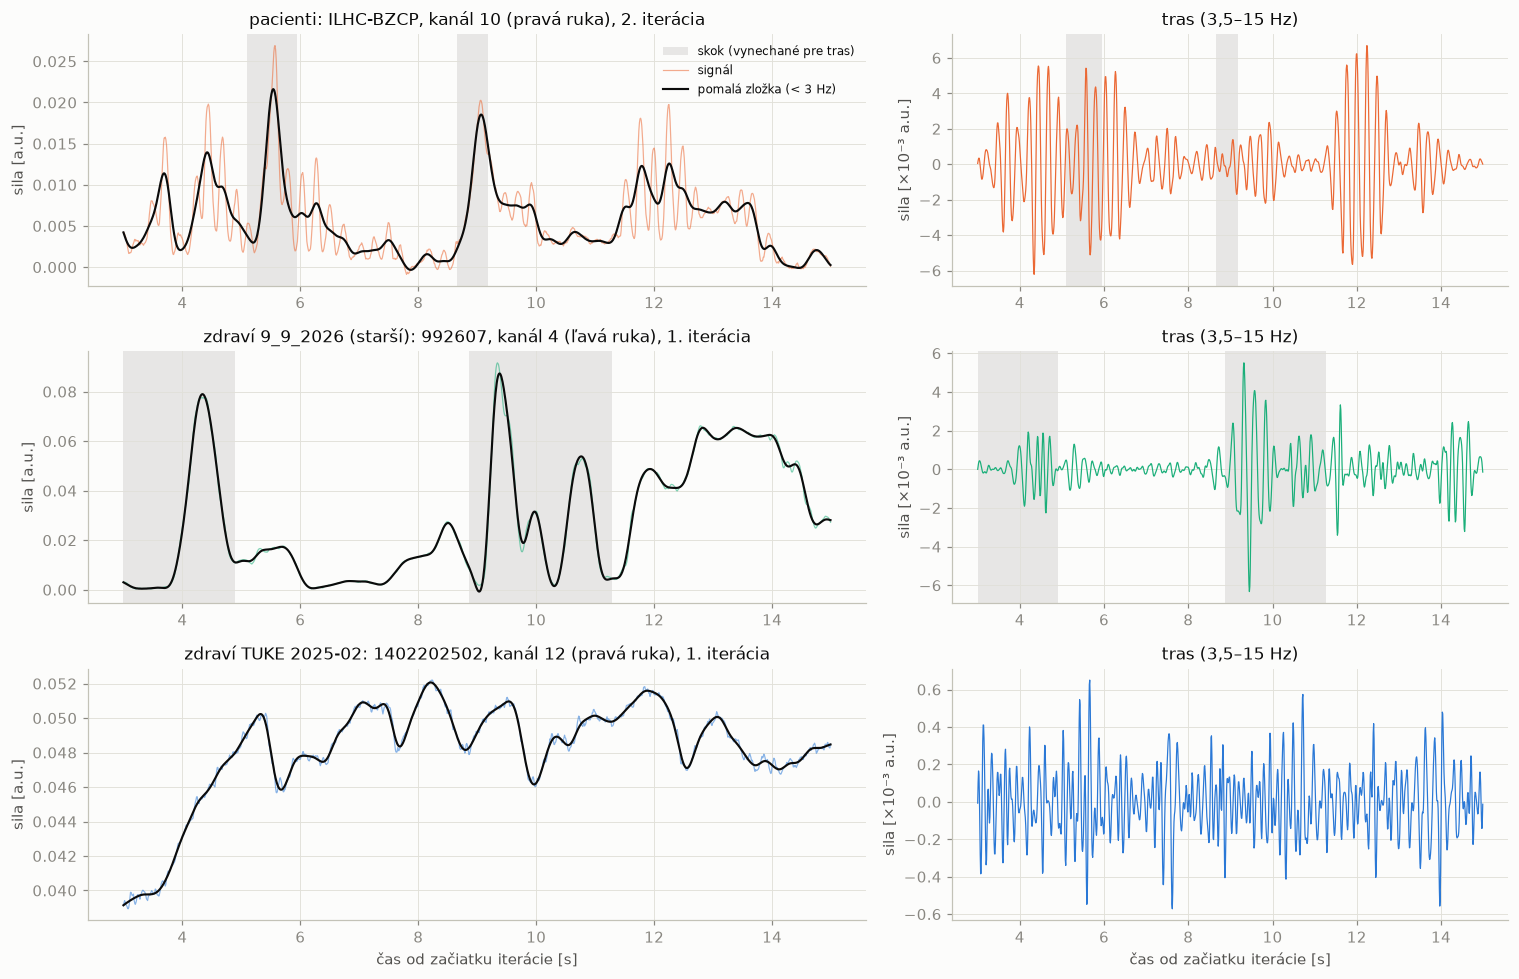

In [9]:
from rehapiano_io import channel_label

def most_active(e):          # prst s najväčšou priemernou silou
    return int(np.argmax(np.abs(X[e].mean(axis=(0, 1)))))

pick = [("pacienti", exams.index[(exams.patient_id == "ILHC-BZCP")][0], 7, 1),
        ("zdraví 9_9_2026 (starší)", typical("zdraví 9_9_2026 (starší)"), None, 0),
        ("zdraví TUKE 2025-02", typical("zdraví TUKE 2025-02"), None, 0)]
fig, axes = plt.subplots(len(pick), 2, figsize=(14, 9), gridspec_kw=dict(width_ratios=[1.4, 1]))
for r, (g, e, c, it) in enumerate(pick):
    c = most_active(e) if c is None else c
    ax = axes[r, 0]
    unsteady = ~STEADY[e, it, :, c]
    ax.fill_between(t, 0, 1, where=unsteady, transform=ax.get_xaxis_transform(), color=MUTED, alpha=0.18, lw=0,
                    label="skok (vynechané pre tras)")
    ax.plot(t, X[e, it, :, c], color=COLORS[g], lw=0.8, alpha=0.55, label="signál")
    ax.plot(t, SLOW[e, it, :, c], color=INK, lw=1.4, label="pomalá zložka (< 3 Hz)")
    ax.set_title(f"{g}: {exams.patient_id[e]}, {channel_label(c)}, {it + 1}. iterácia")
    ax.set_ylabel("sila [a.u.]")
    ax2 = axes[r, 1]
    ax2.plot(t, TREM[e, it, :, c] * 1e3, color=COLORS[g], lw=0.8)
    ax2.fill_between(t, 0, 1, where=unsteady, transform=ax2.get_xaxis_transform(), color=MUTED, alpha=0.18, lw=0)
    ax2.set_title("tras (3,5–15 Hz)")
    ax2.set_ylabel("sila [×10⁻³ a.u.]")
axes[0, 0].legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("čas od začiatku iterácie [s]")
fig.tight_layout(); fig.savefig(FIG_DIR / "12_rozdelenie_zloziek.png", dpi=150); plt.show()

### Kontrola: dajú sa zdraví z TUKE porovnávať s ostatnými?

Zdraví z TUKE (február 2025) hrali inak – takmer bez skokov. Ak meranie trasu v ustálených úsekoch
naozaj odstráni vplyv skokov, potom by **zdraví TUKE vo veku ≥ 50** a **zdraví 9_9_2026** (podobný vek,
iné obdobie) mali mať tras podobný. Porovnáme štandardnú odchýlku trasovej zložky
(medián cez aktívne prsty, priemer cez 4 iterácie) **na celom signáli** a **len v ustálených úsekoch**.

In [10]:
from scipy.stats import mannwhitneyu

def per_exam(values):        # values: (vyšetrenia, iterácie, prsty) -> medián cez aktívne prsty, priemer cez iterácie
    v = np.where(ACTIVE, values, np.nan)
    with np.errstate(all="ignore"):
        return np.nanmean(np.nanmedian(v, axis=2), axis=1)

trem_sd_all = TREM.std(axis=2)
trem_sd_steady = np.full(ACTIVE.shape, np.nan)
for e, i, c in zip(*np.where(ACTIVE)):
    m = STEADY[e, i, :, c]
    if m.any():
        trem_sd_steady[e, i, c] = TREM[e, i, m, c].std()

exams["podiel_ustaleny"] = per_exam(STEADY.mean(axis=2))
exams["tras_SD_cely_1e3"] = per_exam(trem_sd_all) * 1e3
exams["tras_SD_ustaleny_1e3"] = per_exam(trem_sd_steady) * 1e3
exams["porovnanie"] = np.where(exams.podskupina == "zdraví TUKE 2025-02",
                               np.where(exams.vek >= 50, "TUKE ≥ 50", "TUKE < 50"),
                               exams.podskupina.map({"pacienti": "pacienti", "zdraví 9_9_2026 (starší)": "9_9_2026"}))
ORDER = ["TUKE < 50", "TUKE ≥ 50", "9_9_2026", "pacienti"]
display(exams.groupby("porovnanie").agg(vysetreni=("measurement_id", "size"),
                                        podiel_ustaleny=("podiel_ustaleny", "median"),
                                        tras_SD_cely_1e3=("tras_SD_cely_1e3", "median"),
                                        tras_SD_ustaleny_1e3=("tras_SD_ustaleny_1e3", "median")).loc[ORDER].round(3))
a, b = exams.porovnanie == "TUKE ≥ 50", exams.porovnanie == "9_9_2026"
for col in ["tras_SD_cely_1e3", "tras_SD_ustaleny_1e3"]:
    p = mannwhitneyu(exams.loc[a, col].dropna(), exams.loc[b, col].dropna()).pvalue
    print(f"TUKE ≥ 50 vs. 9_9_2026, {col}: Mann-Whitneyho test p = {p:.3f}")

,vysetreni,podiel_ustaleny,tras_SD_cely_1e3,tras_SD_ustaleny_1e3
porovnanie,,,,
TUKE < 50,66,0.993,0.102,0.097
TUKE ≥ 50,12,0.947,0.115,0.087
9_9_2026,12,0.864,0.194,0.099
pacienti,83,0.903,0.223,0.165


TUKE ≥ 50 vs. 9_9_2026, tras_SD_cely_1e3: Mann-Whitneyho test p = 0.030
TUKE ≥ 50 vs. 9_9_2026, tras_SD_ustaleny_1e3: Mann-Whitneyho test p = 0.403


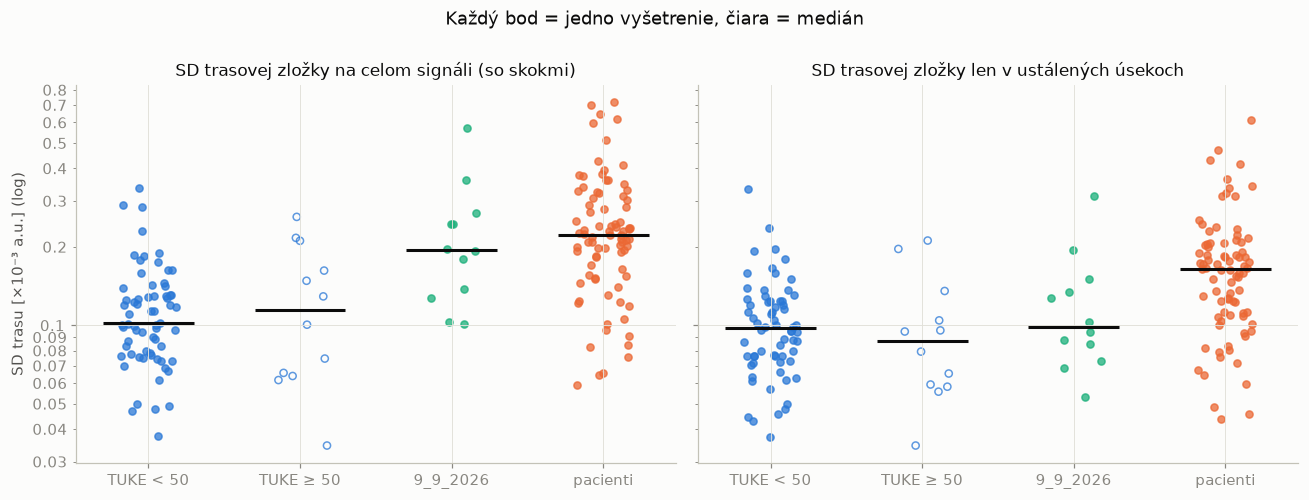

In [11]:
PCOL = {"TUKE < 50": "#2a78d6", "TUKE ≥ 50": "#2a78d6", "9_9_2026": "#1baf7a", "pacienti": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
rng = np.random.default_rng(0)
for ax, col, title in [(axes[0], "tras_SD_cely_1e3", "na celom signáli (so skokmi)"),
                       (axes[1], "tras_SD_ustaleny_1e3", "len v ustálených úsekoch")]:
    for k, g in enumerate(ORDER):
        v = exams.loc[exams.porovnanie == g, col].dropna()
        hollow = g == "TUKE ≥ 50"
        ax.scatter(k + rng.uniform(-0.18, 0.18, len(v)), v, s=22, alpha=0.75,
                   facecolors="none" if hollow else PCOL[g], edgecolors=PCOL[g], linewidths=1)
        ax.hlines(v.median(), k - 0.3, k + 0.3, color=INK, lw=2)
    ax.set_yscale("log"); ax.set_xticks(range(len(ORDER)), ORDER)
    fmt = plt.FuncFormatter(lambda v, _: f"{v:g}")
    ax.yaxis.set_major_formatter(fmt); ax.yaxis.set_minor_formatter(fmt)
    ax.set_title(f"SD trasovej zložky {title}")
axes[0].set_ylabel("SD trasu [×10⁻³ a.u.] (log)")
fig.suptitle("Každý bod = jedno vyšetrenie, čiara = medián", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "13_tras_cely_vs_ustaleny.png", dpi=150); plt.show()

### Záver kroku 3

- Rozdelenie: **pomalá zložka < 3 Hz**, **tras 3,5–15 Hz**; tras sa meria len v ustálených úsekoch
  (relatívny prah skokov 8× typická rýchlosť, min. 0,01 a.u./s; okraj 0,25 s; úseky ≥ 2 s).
- Na **celom signáli** majú zdraví 9_9_2026 tras štatisticky väčší ako rovnako starí zdraví z TUKE – nie
  pre chorobu, ale pre skoky sily, ktoré presakujú do pásma trasu.
- **V ustálených úsekoch** sa tieto dve zdravé skupiny nelíšia. Meranie trasu v ustálených úsekoch teda
  odstraňuje vplyv rozdielneho štýlu hry a **pre príznaky trasu je možné použiť všetkých 90 zdravých**.
- Pre príznaky **pomalej zložky** zostáva hlavným porovnaním pacienti vs. zdraví 9_9_2026 (rovnaké obdobie
  merania); TUKE len ako doplnok.
- Pacientka s trasom (ILHC-BZCP) si pri relatívnom prahu ponechá väčšinu signálu, pri pevnom prahu by
  jej tras z analýzy vypadol.

## 4. Neaktívne prsty a ruky

Niektorí pacienti jednu ruku nepoužívajú alebo len málo. Taká ruka má malú silu, a teda aj malé
kolísanie – v analýze by vyzerala ako „zdravá bez trasu". Preto aktivitu prstov a rúk určíme vopred.

### 4.1 Kanál 9 je zapojený obrátene

Pomalá zložka kanála 9 sa pohybuje **opačne** ako ostatné prsty tej istej ruky a jeho priemerná sila
je takmer vždy záporná. Veľkosťou zodpovedá zrkadlovému kanálu 1 ľavej ruky. Pri stlačení teda hodnota
kanála 9 klesá – pre výpočet úrovne sily mu otočíme znamienko (na tras a spektrá znamienko vplyv nemá).

In [12]:
from rehapiano_features import CHANNEL_SIGN, FINGER_NAMES, LEFT_IDX, RIGHT_IDX

rows = []
for c in range(10):
    hand = LEFT_IDX if c in LEFT_IDX else RIGHT_IDX
    others = [k for k in hand if k != c]
    cors = []
    for e in range(X.shape[0]):
        for i in range(X.shape[1]):
            a, b = SLOW[e, i, :, c], SLOW[e, i][:, others].sum(axis=1)
            if a.std() > 1e-4 and b.std() > 1e-4:
                cors.append(np.corrcoef(a, b)[0, 1])
    raw = X[:, :, :, c].mean(axis=(1, 2))
    rows.append(dict(kanal=FINGER_NAMES[c], korelacia_so_zvyskom_ruky=np.median(cors),
                     median_sily_surova=np.median(raw), podiel_zapornych=(raw < 0).mean()))
display(pd.DataFrame(rows).set_index("kanal").round(3).T)

kanal,k0,k1,k2,k3,k4,k8,k9,k10,k11,k12
korelacia_so_zvyskom_ruky,0.306,0.715,0.682,0.669,0.930,0.245,-0.688,0.582,0.734,0.818
median_sily_surova,0.006,0.010,0.013,0.020,0.049,0.006,-0.010,0.011,0.022,0.048
podiel_zapornych,0.092,0.000,0.035,0.012,0.006,0.121,0.954,0.040,0.006,0.000


### 4.2 Aktívne prsty

Prst, ktorého priemerná sila v iterácii je **≤ 0,003**, sa do trasu nezapočíta (signál je tam takmer len
šum). Nepoužitý prst je však **bežný aj u zdravých** (najslabšie prsty – kanály 0 a 8), preto sám osebe
nie je príznakom choroby.

In [13]:
FL = np.median(LEVELS, axis=1)                     # (vyšetrenia, 10) – medián cez iterácie
H = (exams.skupina == "zdravý").to_numpy()
act = pd.DataFrame({"zdraví": (FL[H] <= FINGER_ACTIVE_MIN).mean(axis=0),
                    "pacienti": (FL[~H] <= FINGER_ACTIVE_MIN).mean(axis=0)}, index=FINGER_NAMES).T
print("Podiel vyšetrení, v ktorých je prst neaktívny (sila ≤ 0,003):")
display(act.round(2))

Podiel vyšetrení, v ktorých je prst neaktívny (sila ≤ 0,003):


,k0,k1,k2,k3,k4,k8,k9,k10,k11,k12
zdraví,0.24,0.03,0.12,0.01,0.01,0.33,0.11,0.12,0.03,0.00
pacienti,0.29,0.01,0.01,0.02,0.00,0.30,0.00,0.01,0.00,0.01


### 4.3 Aktivita rúk

Sila ruky = súčet síl jej piatich prstov (medián cez iterácie). Pre slabšiu ruku sledujeme dve čísla:
jej silu a **pomer rúk** (slabšia / silnejšia). U zdravých sa pomer pohybuje od ~0,2 do 1 – aj zdravý
človek môže tlačiť jednou rukou výrazne slabšie, preto pomer sám nestačí.

Pravidlo (prahy z rozdelenia **zdravých**, 2,5. percentil):
- **nepoužívaná ruka:** súčet síl < 0,01,
- **málo používaná ruka:** sila slabšej ruky **aj** pomer rúk sú pod 2,5. percentilom zdravých,
- inak **v norme**.

In [14]:
from rehapiano_features import hand_levels, hand_status

HAND = hand_levels(FL)                                 # (vyšetrenia, 2)
RATIO = HAND.min(axis=1) / HAND.max(axis=1)
WEAK_LEVEL_THR = float(np.percentile(HAND[H].ravel(), 2.5))
WEAK_RATIO_THR = float(np.percentile(RATIO[H], 2.5))
print(f"Prahy zo zdravých: sila slabšej ruky < {WEAK_LEVEL_THR:.3f}, pomer rúk < {WEAK_RATIO_THR:.2f}")

exams["sila_lava"], exams["sila_prava"] = HAND[:, 0], HAND[:, 1]
exams["pomer_ruk"] = RATIO
exams["slabsia_ruka"] = np.where(HAND[:, 0] < HAND[:, 1], "ľavá", "pravá")
exams["stav_slabsej_ruky"] = hand_status(HAND, RATIO, WEAK_LEVEL_THR, WEAK_RATIO_THR)
display(pd.crosstab(exams.podskupina, exams.stav_slabsej_ruky))
flag = exams[exams.stav_slabsej_ruky != "v norme"].sort_values(["skupina", "pomer_ruk"])
display(flag[["patient_id", "podskupina", "vek", "datum", "sila_lava", "sila_prava", "pomer_ruk",
              "slabsia_ruka", "stav_slabsej_ruky"]].round(3))

Prahy zo zdravých: sila slabšej ruky < 0.068, pomer rúk < 0.56


stav_slabsej_ruky,málo používaná,v norme
podskupina,,
pacienti,12,71
zdraví 9_9_2026 (starší),0,12
zdraví TUKE 2025-02,3,75


,patient_id,podskupina,vek,datum,sila_lava,sila_prava,pomer_ruk,slabsia_ruka,stav_slabsej_ruky
48,EJIT-XSEZ,pacienti,76,2025-07-04 09:25:38,0.099,0.016,0.164,pravá,málo používaná
24,0IKB-27Y1,pacienti,75,2025-04-02 10:04:34,0.022,0.116,0.185,ľavá,málo používaná
15,3OUS-NI9J,pacienti,82,2025-04-17 10:37:08,0.027,0.099,0.271,ľavá,málo používaná
3,3OUS-NI9J,pacienti,82,2025-04-10 13:01:39,0.050,0.175,0.288,ľavá,málo používaná
10,XT2X-WLNW,pacienti,67,2025-03-31 13:13:31,0.102,0.041,0.404,pravá,málo používaná
16,ILHC-BZCP,pacienti,73,2025-04-24 11:31:44,0.094,0.039,0.419,pravá,málo používaná
40,6JRZ-KPE6,pacienti,51,2025-07-04 09:55:16,0.038,0.090,0.420,ľavá,málo používaná
21,OQHZ-N4AV,pacienti,60,2025-04-04 13:04:22,0.136,0.058,0.425,pravá,málo používaná
65,ILHC-BZCP,pacienti,73,2025-05-02 11:12:43,0.102,0.044,0.433,pravá,málo používaná
39,W6JM-R0SG,pacienti,58,2025-06-23 13:35:50,0.103,0.048,0.467,pravá,málo používaná


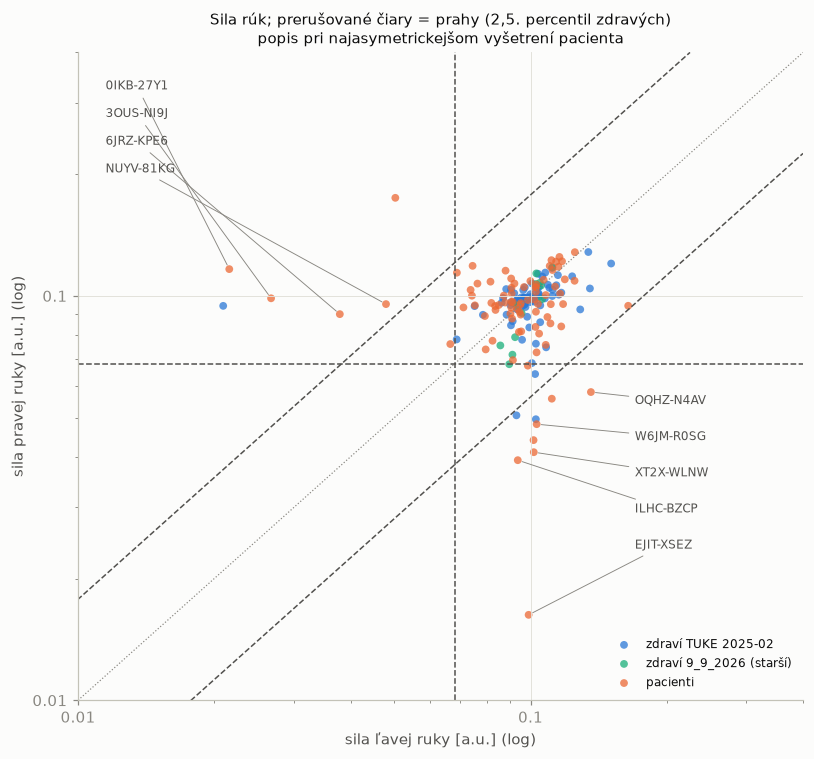

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 7))
for g in GROUPS:
    s = exams[exams.podskupina == g]
    ax.scatter(s.sila_lava, s.sila_prava, s=26, alpha=0.75, color=COLORS[g], label=g, edgecolors="none")
lim = (0.01, 0.4)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
v = np.geomspace(*lim, 50)
ax.plot(v, v, color=MUTED, lw=0.8, ls=":")
ax.plot(v, v * WEAK_RATIO_THR, color=INK2, lw=1, ls="--"); ax.plot(v * WEAK_RATIO_THR, v, color=INK2, lw=1, ls="--")
ax.axvline(WEAK_LEVEL_THR, color=INK2, lw=1, ls="--"); ax.axhline(WEAK_LEVEL_THR, color=INK2, lw=1, ls="--")
pf = flag[flag.skupina == "pacient"].sort_values("pomer_ruk").drop_duplicates("patient_id")  # 1 popis na pacienta
# popisy v prázdnych oblastiach grafu so šípkou k bodu (aby sa neprekrývali s inými bodmi)
for side, x0, ys in [("ľavá", 0.0115, np.geomspace(0.33, 0.15, 6)), ("pravá", 0.17, np.geomspace(0.055, 0.016, 7))]:
    sub = (pf[pf.slabsia_ruka == side].sort_values("sila_lava") if side == "ľavá"
           else pf[pf.slabsia_ruka == side].sort_values("sila_prava", ascending=False))
    for (_, r), y in zip(sub.iterrows(), ys):
        ax.annotate(r.patient_id, (r.sila_lava, r.sila_prava), xytext=(x0, y), textcoords="data", fontsize=8,
                    color=INK2, va="center", arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6, shrinkB=3))
fmt = plt.FuncFormatter(lambda v, _: f"{v:g}")
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(fmt); a.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("sila ľavej ruky [a.u.] (log)"); ax.set_ylabel("sila pravej ruky [a.u.] (log)")
ax.set_title("Sila rúk; prerušované čiary = prahy (2,5. percentil zdravých)\npopis pri najasymetrickejšom vyšetrení pacienta", fontsize=10)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "14_aktivita_ruk.png", dpi=150); plt.show()

Body v rohoch mimo prerušovaných čiar (vľavo hore a vpravo dole) sú vyšetrenia, kde je jedna ruka slabá
v absolútnej sile aj v pomere k druhej ruke.

### 4.4 Tras závisí od sily, ktorou prst tlačí

Čím silnejšie prst tlačí, tým väčšie je kolísanie v pásme trasu – aj u zdravých. Slabšia ruka by preto
mala menší tras len preto, že tlačí slabšie. Porovnanie pacientov a zdravých **pri rovnakej sile**
(prsty rozdelené do 5 skupín podľa sily) ukáže, či rozdiel nie je spôsobený len silou.

skupina,pacient,zdravý,pomer pacient/zdravý
kvintil_sily,,,
"(0.00201, 0.00799]",0.092,0.071,1.304
"(0.00799, 0.0122]",0.091,0.062,1.455
"(0.0122, 0.019]",0.112,0.064,1.758
"(0.019, 0.0375]",0.168,0.105,1.588
"(0.0375, 0.18]",0.321,0.174,1.850


zdravý: Spearmanov koeficient sila ~ tras = 0.43
pacient: Spearmanov koeficient sila ~ tras = 0.46


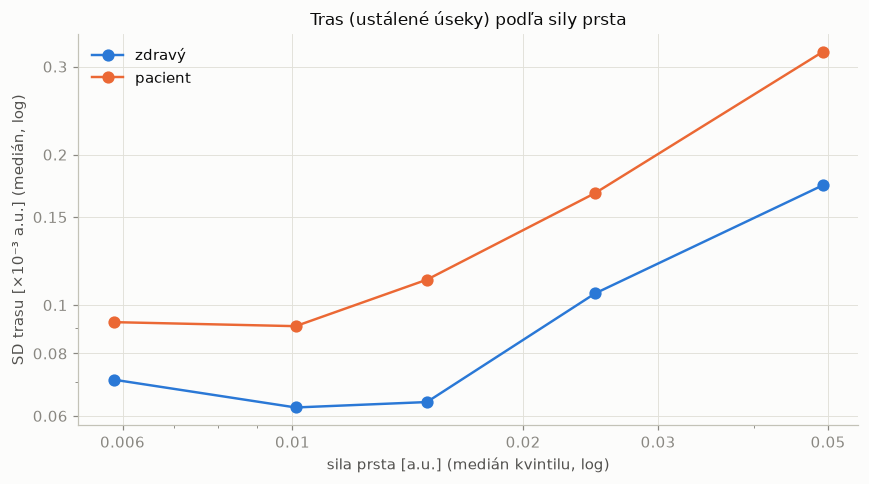

In [16]:
from scipy.stats import spearmanr

pts = []
for e, i, c in zip(*np.where(ACTIVE)):
    m = STEADY[e, i, :, c]
    if m.sum() >= 200:
        pts.append((exams.skupina[e], LEVELS[e, i, c], TREM[e, i, m, c].std() * 1e3))
pts = pd.DataFrame(pts, columns=["skupina", "sila", "tras_SD_1e3"])
pts["kvintil_sily"] = pd.qcut(pts.sila, 5)
tab = pts.pivot_table(index="kvintil_sily", columns="skupina", values="tras_SD_1e3", aggfunc="median", observed=True)
tab["pomer pacient/zdravý"] = tab["pacient"] / tab["zdravý"]
display(tab.round(3))
for g in ["zdravý", "pacient"]:
    s = pts[pts.skupina == g]
    print(f"{g}: Spearmanov koeficient sila ~ tras = {spearmanr(s.sila, s.tras_SD_1e3).correlation:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
centers = pts.groupby("kvintil_sily", observed=True).sila.median()
for g, col in [("zdravý", "#2a78d6"), ("pacient", "#eb6834")]:
    ax.plot(centers.values, tab[g].values, marker="o", ms=7, color=col, label=g)
ax.set_xscale("log"); ax.set_yscale("log")
fmt = plt.FuncFormatter(lambda v, _: f"{v:g}")
ax.set_xticks([0.006, 0.01, 0.02, 0.03, 0.05]); ax.set_yticks([0.06, 0.08, 0.1, 0.15, 0.2, 0.3])
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(fmt); a.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("sila prsta [a.u.] (medián kvintilu, log)"); ax.set_ylabel("SD trasu [×10⁻³ a.u.] (medián, log)")
ax.set_title("Tras (ustálené úseky) podľa sily prsta")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "15_tras_podla_sily.png", dpi=150); plt.show()

### Záver kroku 4

- **Kanál 9** má otočené znamienko – opravené pri výpočte úrovne sily.
- **Neaktívny prst** (sila ≤ 0,003) sa do trasu nezapočíta; je bežný aj u zdravých, nie je príznakom.
- **Úplne nepoužívanú ruku nemá nikto** v datasete. **Málo používanú** ruku (sila aj pomer rúk pod 2,5.
  percentilom zdravých) má niekoľko pacientov; u zdravých sa to stáva len výnimočne (z definície ~2,5 %).
  Stav ruky, sila slabšej ruky a pomer rúk pôjdu do tabuľky ako príznaky.
- **Tras rastie so silou prsta** (aj u zdravých), ale pri rovnakej sile majú pacienti tras väčší vo všetkých
  piatich skupinách sily. V kroku 5 preto okrem absolútnej SD trasu vypočítame aj **tras upravený na silu**
  (pomer k typickej hodnote zdravých pri rovnakej sile), aby slabo používaná ruka nevyzerala ako „bez trasu".
- Tras človeka sa bude brať z **ruky s najväčším (na silu upraveným) trasom** spomedzi používaných rúk.

## 5. Príznaky pre každého človeka

Postup: **prst × iterácia → iterácia → vyšetrenie → človek**.

1. Pre každý aktívny prst v každej iterácii sa vypočítajú príznaky trasu (len z ustálených úsekov).
2. V každej iterácii sa vyberie **prst s najväčším trasom upraveným na silu** (tým aj ruka s trasom);
   pomalá zložka sa počíta zo **súčtu síl ruky** a spriemeruje sa cez obe ruky.
3. Za vyšetrenie: **priemer a SD cez 4 iterácie** (iterácie sa nespriemerúvajú ako signály – tras by sa
   vyrušil, priemerujú sa až vypočítané čísla).
4. Za človeka: priemer cez jeho vyšetrenia (pacienti majú väčšinou 2).

| Príznak | Význam |
|---|---|
| `tras_SD` | SD trasovej zložky (3,5–15 Hz) v ustálených úsekoch – veľkosť trasu [a.u.] |
| `tras_relativny` | koľkokrát je tras vybraného prsta väčší ako typický tras zdravých **pri rovnakej sile prsta**; vyberá sa maximum z ~10 prstov, preto aj zdraví majú ~2,5 |
| `tras_relativny_median` | to isté, ale medián cez všetky aktívne prsty (zdraví ≈ 1) – či sa trasie celá ruka |
| `tras_f_vrchol` | frekvencia najvyššieho vrcholu v pásme 3,5–15 Hz [Hz] |
| `tras_f_priemer` | priemerná (ťažisková) frekvencia pásma 3,5–15 Hz [Hz] |
| `tras_ostrost` | podiel výkonu v okolí ±0,5 Hz vrcholu – rytmický tras má ostrý vrchol, šum nie |
| `tras_k_pomaly` | pomer SD trasu a SD pomalej zložky toho istého prsta |
| `tras_f_SD_cas` | SD frekvencie vrcholu v 2 s oknách (spektrogram) – stabilita frekvencie trasu v čase [Hz] |
| `tras_cas_podiel` | podiel 2 s okien, v ktorých je tras nad 95. percentilom okien zdravých – ako často je tras prítomný |
| `pomaly_uroven` | priemerná sila ruky (súčet prstov) |
| `pomaly_SD` | SD pomalej zložky (< 3 Hz) sily ruky – ako veľmi sila „kolíše" pri ovládaní hry |
| `pomaly_f_priemer` | priemerná frekvencia pomalej zložky (0,25–3 Hz) – ako často človek silu opravuje |
| `skoky_za_min` | počet prudkých zmien sily za minútu |
| `podiel_ustaleny` | podiel času ustáleného držania sily |
| `…_SD_iter` | SD daného príznaku medzi 4 iteráciami – stálosť človeka |
| `sila_lava`, `sila_prava`, `pomer_ruk`, `sila_slabsej_ruky`, `stav_slabsej_ruky` | aktivita rúk (krok 4) |

In [17]:
import time
from rehapiano_features import (SLOW_COLS, TREMOR_COLS, compute_finger_features, compute_iteration_features,
                                compute_person_features)

t_start = time.time()
FING, REF = compute_finger_features(X, exams)
ITERS = compute_iteration_features(X, FING)
EXAMS_F, PERSON = compute_person_features(exams, ITERS)
print(f"prst × iterácia: {len(FING)} riadkov | vyšetrenie × iterácia: {len(ITERS)} | ľudia: {len(PERSON)} "
      f"| čas {time.time() - t_start:.0f} s")
print(f"Prah okna s trasom (95. percentil zdravých, tras upravený na silu): {FING.attrs['episode_thr']:.2f}")
print("Chýbajúce hodnoty v tabuľke ľudí:", int(PERSON.isna().sum().sum()))

prst × iterácia: 6284 riadkov | vyšetrenie × iterácia: 692 | ľudia: 138 | čas 54 s
Prah okna s trasom (95. percentil zdravých, tras upravený na silu): 3.10
Chýbajúce hodnoty v tabuľke ľudí: 0


In [18]:
FEATURES = TREMOR_COLS + SLOW_COLS
med = PERSON.groupby("podskupina")[FEATURES].median().T[GROUPS]
med.columns = [f"{c} (n={int((PERSON.podskupina == c).sum())})" for c in GROUPS]
print("Mediány príznakov podľa skupín (jeden človek = jedna hodnota):")
display(med.style.format("{:.4g}"))

Mediány príznakov podľa skupín (jeden človek = jedna hodnota):


,zdraví TUKE 2025-02 (n=78),zdraví 9_9_2026 (starší) (n=12),pacienti (n=48)
tras_SD,0.0001869,0.0002223,0.0004002
tras_relativny,2.478,2.515,4.344
tras_relativny_median,1.015,1.262,1.871
tras_f_vrchol,4.141,4.203,4.523
tras_f_priemer,7.007,6.279,6.575
tras_ostrost,0.2281,0.2821,0.2675
tras_k_pomaly,0.2083,0.1174,0.1393
tras_f_SD_cas,1.755,1.071,1.418
tras_cas_podiel,0.1113,0.1887,0.6469
pomaly_uroven,0.09869,0.1002,0.09728


Prvý pohľad (podrobné porovnanie je v kroku 7):
- **príznaky trasu** sú u pacientov vyššie ako v oboch zdravých skupinách, ktoré sú si navzájom podobné
  (čo je v súlade s krokom 3: tras v ustálených úsekoch nezávisí od obdobia merania),
- **príznaky pomalej zložky** (`pomaly_SD`, `skoky_za_min`) sú u pacientov podobné ako u zdravých
  9_9_2026, ale veľmi odlišné od zdravých TUKE – to je rozdiel obdobia merania, nie choroby.

In [19]:
show = ["patient_id", "podskupina", "vek", "tras_relativny", "tras_relativny_median", "tras_f_vrchol",
        "tras_ostrost", "tras_cas_podiel", "pomaly_SD", "skoky_za_min", "ruka_trasu", "prst_trasu", "stav_slabsej_ruky"]
print("Príklady: pacientka s trasom, pacient s málo používanou rukou, zdravá z rovnakého obdobia")
display(PERSON[PERSON.patient_id.isin(["ILHC-BZCP", "EJIT-XSEZ", "992612"])][show].set_index("patient_id").round(3))

Príklady: pacientka s trasom, pacient s málo používanou rukou, zdravá z rovnakého obdobia


,podskupina,vek,tras_relativny,tras_relativny_median,tras_f_vrchol,tras_ostrost,tras_cas_podiel,pomaly_SD,skoky_za_min,ruka_trasu,prst_trasu,stav_slabsej_ruky
patient_id,,,,,,,,,,,,
992612,zdraví 9_9_2026 (starší),74,3.437,1.171,4.188,0.286,0.414,0.008,8.750,pravá,k8,v norme
EJIT-XSEZ,pacienti,76,4.507,2.462,5.312,0.390,0.513,0.011,9.688,pravá,k12,málo používaná
ILHC-BZCP,pacienti,73,29.135,6.307,4.078,0.814,0.986,0.031,7.188,pravá,k10,málo používaná


## 6. Tabuľka `features.csv`

Uloží sa **jeden riadok na človeka** (vstup pre rozhodovanie pacient / zdravý) a pomocná tabuľka
**jeden riadok na vyšetrenie × iteráciu** (`features_iteracie.csv`) na kontrolu, z čoho priemery vznikli.
Formát ako súbory v `datasets`: oddeľovač `;`, desatinná bodka.

In [20]:
ID = ["patient_id", "skupina", "podskupina", "obdobie", "vek", "pohlavie", "pocet_vysetreni"]
HANDS = ["sila_lava", "sila_prava", "pomer_ruk", "sila_slabsej_ruky", "stav_slabsej_ruky", "ruka_trasu", "prst_trasu"]
SD_ITER = [c for c in PERSON.columns if c.endswith("_SD_iter")]
features = PERSON[ID + FEATURES + SD_ITER + HANDS]
features.to_csv("features.csv", sep=";", index=False, float_format="%.6g", encoding="utf-8-sig")

it = ITERS.merge(EXAMS_F[["patient_id", "skupina", "podskupina", "measurement_id"]], left_on="vysetrenie",
                 right_index=True).drop(columns="vysetrenie")
it = it[["patient_id", "skupina", "podskupina", "measurement_id", "iteracia"] + FEATURES + ["ruka_trasu", "prst_trasu"]]
it.to_csv("features_iteracie.csv", sep=";", index=False, float_format="%.6g", encoding="utf-8-sig")

print(f"features.csv: {features.shape[0]} riadkov × {features.shape[1]} stĺpcov")
print(f"features_iteracie.csv: {it.shape[0]} riadkov × {it.shape[1]} stĺpcov")
display(features.head())

features.csv: 138 riadkov × 32 stĺpcov
features_iteracie.csv: 692 riadkov × 21 stĺpcov


,patient_id,skupina,podskupina,obdobie,vek,pohlavie,pocet_vysetreni,tras_SD,tras_relativny,tras_relativny_median,...,tras_relativny_SD_iter,tras_f_vrchol_SD_iter,pomaly_SD_SD_iter,sila_lava,sila_prava,pomer_ruk,sila_slabsej_ruky,stav_slabsej_ruky,ruka_trasu,prst_trasu
0,0HXU-5CYJ,pacient,pacienti,2025-03 a neskôr,67,male,2,0.000170,2.426892,1.099092,...,1.036720,0.646253,0.020757,0.114426,0.095414,0.834658,0.095414,v norme,pravá,k0
1,0IKB-27Y1,pacient,pacienti,2025-03 a neskôr,75,female,1,0.001645,10.809723,5.939375,...,7.935212,1.374526,0.021308,0.021584,0.116466,0.185326,0.021584,málo používaná,pravá,k12
2,1302202501,zdravý,zdraví TUKE 2025-02,2025-02,23,female,1,0.000139,1.959340,0.856683,...,0.584384,0.471865,0.008768,0.101741,0.099145,0.974485,0.099145,v norme,pravá,k8
3,1302202502,zdravý,zdraví TUKE 2025-02,2025-02,21,male,1,0.000175,2.371131,0.873673,...,0.447779,0.709864,0.001143,0.090477,0.103470,0.874434,0.090477,v norme,pravá,k8
4,1302202503,zdravý,zdraví TUKE 2025-02,2025-02,22,female,1,0.000285,4.187919,1.422595,...,2.792027,0.236621,0.048184,0.105059,0.094723,0.901610,0.094723,v norme,ľavá,k0


## 7. Porovnanie skupín: ktoré príznaky odlišujú pacientov?

Pre každý príznak: **Mann-Whitneyho test** (pacienti vs. zdraví) a **AUC** – pravdepodobnosť, že náhodne
vybraný pacient má vyššiu hodnotu ako náhodne vybraný zdravý človek. AUC = 0,5 znamená, že príznak
skupiny nerozlišuje; AUC blízko 1 (alebo 0) znamená dobré rozlíšenie (pri AUC < 0,5 majú pacienti
hodnoty nižšie). 95 % interval spoľahlivosti AUC je z bootstrapu (2000 opakovaní), p-hodnoty sú
korigované na viacnásobné testovanie (Holmova metóda).

S kým porovnávame (podľa záverov krokov 2–4):
- **príznaky trasu** – so **všetkými 90 zdravými**; aby vek nehral rolu, aj len so **zdravými ≥ 50 rokov**
  (12 z 9_9_2026 + 12 z TUKE) a so zdravými 9_9_2026,
- **príznaky pomalej zložky** – len so **zdravými 9_9_2026** (rovnaké obdobie merania; TUKE hrali inak),
- **príznaky rúk** – so všetkými zdravými (úroveň sily sa medzi obdobiami nelíši).

In [21]:
from scipy.stats import mannwhitneyu

P = PERSON.copy()
PAT = (P.skupina == "pacient").to_numpy()
HEALTHY = ~PAT
OLDER = HEALTHY & (P.vek >= 50).to_numpy()
H99 = (P.podskupina == "zdraví 9_9_2026 (starší)").to_numpy()


def auc(a, b):
    return mannwhitneyu(a, b).statistic / (len(a) * len(b))


def boot_ci(a, b, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    return np.percentile([auc(rng.choice(a, len(a)), rng.choice(b, len(b))) for _ in range(n)], [2.5, 97.5])


FAMILIES = [
    ("tras", ["tras_SD", "tras_relativny", "tras_relativny_median", "tras_cas_podiel", "tras_relativny_SD_iter",
              "tras_f_vrchol", "tras_ostrost", "tras_f_priemer", "tras_k_pomaly", "tras_f_SD_cas", "tras_f_vrchol_SD_iter"],
     HEALTHY, "všetci zdraví"),
    ("pomalá zložka", ["pomaly_uroven", "pomaly_SD", "pomaly_f_priemer", "skoky_za_min", "podiel_ustaleny", "pomaly_SD_SD_iter"],
     H99, "zdraví 9_9_2026"),
    ("ruky", ["pomer_ruk", "sila_slabsej_ruky"], HEALTHY, "všetci zdraví"),
]
rows = []
for fam, cols, ref, ref_name in FAMILIES:
    for c in cols:
        a, b = P.loc[PAT, c], P.loc[ref, c]
        lo, hi = boot_ci(a, b)
        r = dict(skupina=fam, priznak=c, porovnanie_s=ref_name, median_pacienti=a.median(), median_zdravi=b.median(),
                 AUC=auc(a, b), AUC_CI=f"{lo:.2f}–{hi:.2f}", AUC_lo=lo, AUC_hi=hi, p=mannwhitneyu(a, b).pvalue)
        if fam == "tras":
            r["AUC_vs_zdravi_50plus"] = auc(a, P.loc[OLDER, c])
            r["AUC_vs_9_9_2026"] = auc(a, P.loc[H99, c])
        rows.append(r)
STATS = pd.DataFrame(rows)
order = np.argsort(STATS.p.values)
holm, running = np.empty(len(STATS)), 0.0
for rank, idx in enumerate(order):
    running = max(running, min(1.0, (len(STATS) - rank) * STATS.p.values[idx]))
    holm[idx] = running
STATS["p_Holm"] = holm
print(f"pacienti: {PAT.sum()}, zdraví: {HEALTHY.sum()} (z toho ≥ 50 rokov: {OLDER.sum()}, 9_9_2026: {H99.sum()})")
display(STATS.drop(columns=["AUC_lo", "AUC_hi"]).style.format(
    {"median_pacienti": "{:.4g}", "median_zdravi": "{:.4g}", "AUC": "{:.2f}", "p": "{:.1e}", "p_Holm": "{:.1e}",
     "AUC_vs_zdravi_50plus": "{:.2f}", "AUC_vs_9_9_2026": "{:.2f}"}, na_rep="–"))

pacienti: 48, zdraví: 90 (z toho ≥ 50 rokov: 24, 9_9_2026: 12)


,skupina,priznak,porovnanie_s,median_pacienti,median_zdravi,AUC,AUC_CI,p,AUC_vs_zdravi_50plus,AUC_vs_9_9_2026,p_Holm
0,tras,tras_SD,všetci zdraví,0.0004002,0.00019,0.81,0.73–0.88,2.4e-09,0.81,0.76,4.6e-08
1,tras,tras_relativny,všetci zdraví,4.344,2.478,0.80,0.72–0.88,5.9e-09,0.82,0.82,1.1e-07
2,tras,tras_relativny_median,všetci zdraví,1.871,1.032,0.79,0.71–0.88,1.3e-08,0.76,0.72,2.2e-07
3,tras,tras_cas_podiel,všetci zdraví,0.6469,0.1334,0.77,0.68–0.85,1.3e-07,0.82,0.83,2.0e-06
4,tras,tras_relativny_SD_iter,všetci zdraví,1.174,0.5219,0.76,0.68–0.84,4.2e-07,0.72,0.72,6.3e-06
5,tras,tras_f_vrchol,všetci zdraví,4.523,4.172,0.62,0.53–0.71,2.0e-02,0.66,0.60,1.6e-01
6,tras,tras_ostrost,všetci zdraví,0.2675,0.2398,0.64,0.54–0.73,8.7e-03,0.49,0.36,7.9e-02
7,tras,tras_f_priemer,všetci zdraví,6.575,6.881,0.36,0.27–0.46,6.0e-03,0.53,0.62,6.0e-02
8,tras,tras_k_pomaly,všetci zdraví,0.1393,0.1955,0.34,0.25–0.45,2.5e-03,0.48,0.59,3.3e-02
9,tras,tras_f_SD_cas,všetci zdraví,1.418,1.648,0.35,0.26–0.44,4.1e-03,0.58,0.75,4.5e-02


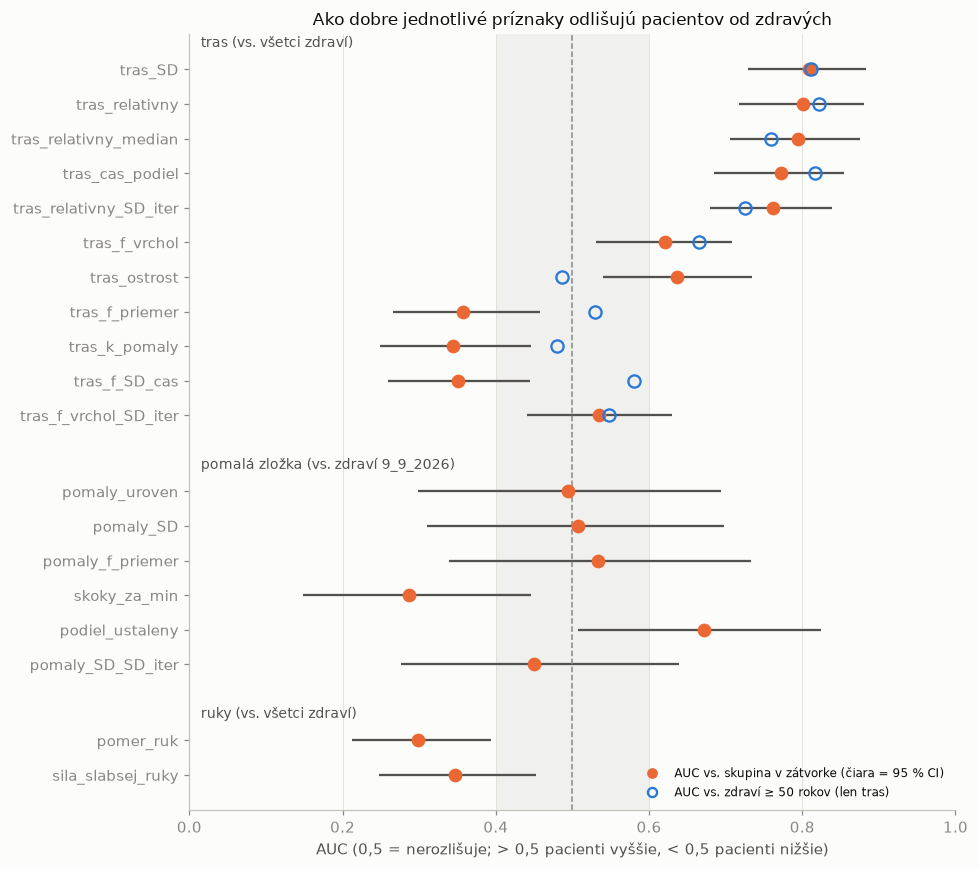

In [22]:
fig, ax = plt.subplots(figsize=(9, 8))
labels, y = [], 0
yticks = []
for fam, cols, _, ref_name in FAMILIES:
    sub = STATS[STATS.skupina == fam]
    ax.text(0.015, y - 0.15, f"{fam} (vs. {ref_name})", fontsize=9, color=INK2, transform=ax.get_yaxis_transform())
    y -= 0.8
    for _, r in sub.iterrows():
        ax.hlines(y, r.AUC_lo, r.AUC_hi, color=INK2, lw=1.5)
        ax.plot(r.AUC, y, "o", ms=8, color="#eb6834", zorder=3)
        if fam == "tras":
            ax.plot(r.AUC_vs_zdravi_50plus, y, "o", ms=8, mfc="none", mec="#2a78d6", mew=1.5, zorder=3)
        yticks.append(y); labels.append(r.priznak)
        y -= 1
    y -= 0.4
ax.axvline(0.5, color=MUTED, lw=1, ls="--")
ax.axvspan(0.4, 0.6, color=MUTED, alpha=0.10, lw=0)
ax.set_yticks(yticks, labels); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC (0,5 = nerozlišuje; > 0,5 pacienti vyššie, < 0,5 pacienti nižšie)")
ax.plot([], [], "o", color="#eb6834", label="AUC vs. skupina v zátvorke (čiara = 95 % CI)")
ax.plot([], [], "o", mfc="none", mec="#2a78d6", mew=1.5, label="AUC vs. zdraví ≥ 50 rokov (len tras)")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Ako dobre jednotlivé príznaky odlišujú pacientov od zdravých")
fig.tight_layout(); fig.savefig(FIG_DIR / "16_auc_priznakov.png", dpi=150); plt.show()

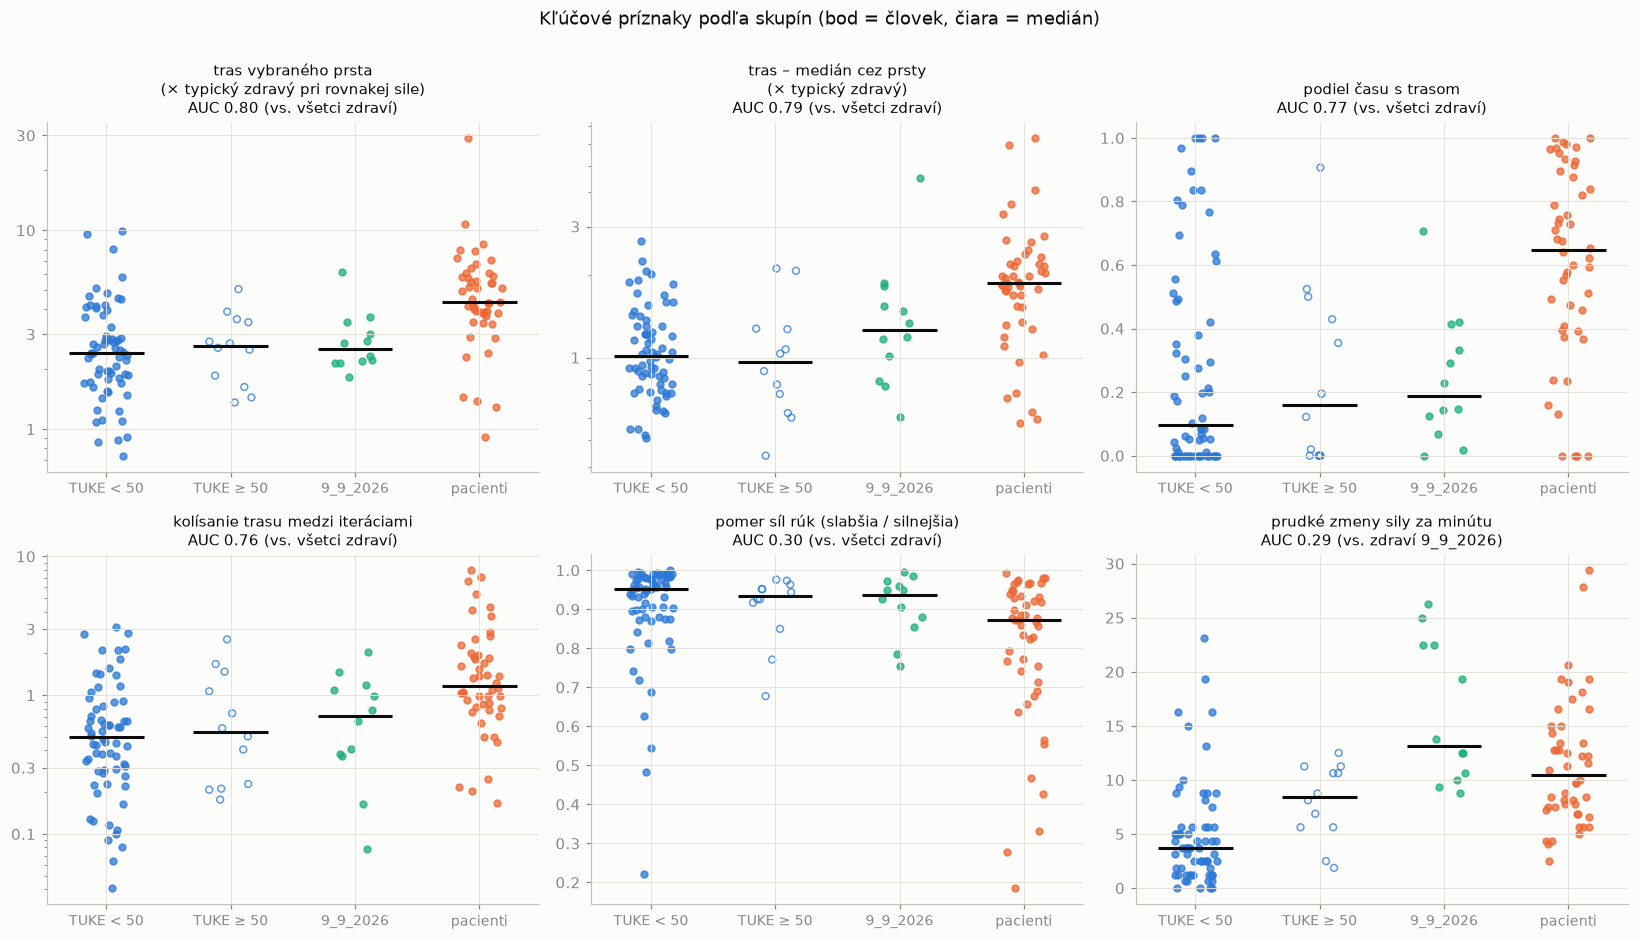

In [23]:
KEY = [("tras_relativny", "tras vybraného prsta\n(× typický zdravý pri rovnakej sile)", True),
       ("tras_relativny_median", "tras – medián cez prsty\n(× typický zdravý)", True),
       ("tras_cas_podiel", "podiel času s trasom", False),
       ("tras_relativny_SD_iter", "kolísanie trasu medzi iteráciami", True),
       ("pomer_ruk", "pomer síl rúk (slabšia / silnejšia)", False),
       ("skoky_za_min", "prudké zmeny sily za minútu", False)]
P["porovnanie"] = np.where(P.podskupina == "zdraví TUKE 2025-02", np.where(P.vek >= 50, "TUKE ≥ 50", "TUKE < 50"),
                           P.podskupina.map({"pacienti": "pacienti", "zdraví 9_9_2026 (starší)": "9_9_2026"}))
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
rng = np.random.default_rng(1)
for ax, (col, title, logy) in zip(axes.flat, KEY):
    for k, g in enumerate(ORDER):
        v = P.loc[P.porovnanie == g, col].dropna()
        hollow = g == "TUKE ≥ 50"
        ax.scatter(k + rng.uniform(-0.18, 0.18, len(v)), v, s=20, alpha=0.75,
                   facecolors="none" if hollow else PCOL[g], edgecolors=PCOL[g], linewidths=1)
        ax.hlines(v.median(), k - 0.3, k + 0.3, color=INK, lw=2)
    if logy:
        ax.set_yscale("log")
        fmt = plt.FuncFormatter(lambda v, _: f"{v:g}")
        ax.yaxis.set_major_locator(plt.LogLocator(subs=(1.0, 3.0)))
        ax.yaxis.set_major_formatter(fmt); ax.yaxis.set_minor_formatter(plt.NullFormatter())
    a = STATS.set_index("priznak").loc[col]
    ax.set_title(f"{title}\nAUC {a.AUC:.2f} (vs. {a.porovnanie_s})", fontsize=10)
    ax.set_xticks(range(len(ORDER)), ORDER, fontsize=9)
fig.suptitle("Kľúčové príznaky podľa skupín (bod = človek, čiara = medián)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "17_klucove_priznaky.png", dpi=150); plt.show()

In [24]:
# Koľko pacientov má tras mimo rozsahu zdravých (nad 95. percentilom zdravých ≥ 50 rokov)?
rows = []
for col in ["tras_relativny", "tras_relativny_median", "tras_cas_podiel"]:
    thr = np.percentile(P.loc[OLDER, col], 95)
    rows.append(dict(priznak=col, prah_95_percentil_zdravych_50plus=thr,
                     pacienti_nad_prahom=f"{(P.loc[PAT, col] > thr).sum()} / {PAT.sum()}",
                     zdravi_nad_prahom=f"{(P.loc[HEALTHY, col] > thr).sum()} / {HEALTHY.sum()}"))
display(pd.DataFrame(rows).round(3))

,priznak,prah_95_percentil_zdravych_50plus,pacienti_nad_prahom,zdravi_nad_prahom
0,tras_relativny,4.885,22 / 48,7 / 90
1,tras_relativny_median,2.103,16 / 48,4 / 90
2,tras_cas_podiel,0.680,22 / 48,14 / 90


### Záver kroku 7

**Najlepšie odlišujú pacientov príznaky trasu** (AUC ≈ 0,77–0,81): `tras_SD`, `tras_relativny`,
`tras_relativny_median`, `tras_cas_podiel` a `tras_relativny_SD_iter` (pacienti majú tras väčší, častejší
a menej stály medzi iteráciami). Rozdiel zostáva aj pri porovnaní so **zdravými ≥ 50 rokov** a so zdravými
9_9_2026 (AUC ≈ 0,72–0,83) – nie je teda spôsobený vekom ani obdobím merania.

**Aktivita rúk** pomáha tiež: pacienti majú menší pomer síl rúk (AUC 0,30, t. j. 0,70 opačným smerom)
a slabšiu slabšiu ruku.

**Pomalá zložka (ovládanie hry) pacientov od zdravých z rovnakého obdobia neodlišuje** (AUC ≈ 0,5);
jediný náznak je menej prudkých zmien sily u pacientov (`skoky_za_min`), po korekcii na viacnásobné
testovanie však nevýznamný (vzorka 12 zdravých je malá).

**Nespoľahlivé príznaky:** `tras_f_priemer`, `tras_k_pomaly`, `tras_f_SD_cas` a `tras_ostrost` vyzerajú
odlišne len voči všetkým zdravým, nie voči rovnako starým – odrážajú vek alebo obdobie, nie chorobu.
Frekvencia vrcholu (`tras_f_vrchol`) rozlišuje len slabo – väčšina pacientov nemá výrazný rytmický tras
(dataset obsahuje rôzne diagnózy, nielen Parkinsonovu chorobu).

**Obmedzenia:** referencia „typický zdravý pri rovnakej sile" a prah epizódy trasu boli určené na tých
istých zdravých, s ktorými sa porovnáva – AUC týchto príznakov môže byť mierne optimistické (príznak
`tras_SD` bez tejto kalibrácie má však podobné AUC 0,81). Skutočnú presnosť rozhodovania ukáže až
krížová validácia v ďalšej úlohe.

**Pre rozhodovanie pacient / zdravý odporúčam:** `tras_relativny`, `tras_relativny_median`,
`tras_cas_podiel`, `tras_relativny_SD_iter`, `pomer_ruk`, `sila_slabsej_ruky` (+ spektrogram ako vizuálna
kontrola trasu).